## Análisis de modelos

## SVM

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from itertools import product

from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
import time
import os
import joblib

In [2]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


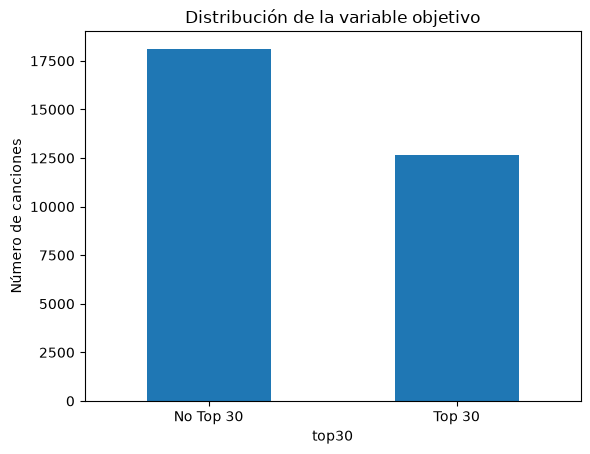

In [3]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Separamos train y test:

In [4]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(18462, 13) (6154, 13) (6155, 13)
En train: 41.14 % En validación:  41.14 %   en test: 41.14 %


In [5]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(18462, 13)

Columnas con nulos:
spotify_track_duration_ms    2175
spotify_track_explicit       2175
danceability                 2215
key                          2215
loudness                     2215
mode                         2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
time_signature               2215
dtype: int64


## Aplicamos el análisis en X_train

In [6]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
loudness                     2215
key                          2215
mode                         2215
time_signature               2215
spotify_track_duration_ms    2175
spotify_track_explicit       2175
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6010645657659875), 'speechiness': np.float64(0.0900256662768511), 'instrumentalness': np.float64(0.0328892274376808), 'tempo': np.float64(120.93728928417553), 'loudness': np.float64(-8.166), 'key': np.float64(0.

## Rellenamos nulos en X_val 

In [7]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 762
speechiness                  762
instrumentalness             762
tempo                        762
loudness                     762
key                          762
mode                         762
time_signature               762
spotify_track_duration_ms    753
spotify_track_explicit       753
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


## Rellenamos nulos en X_test

In [8]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 732
speechiness                  732
instrumentalness             732
tempo                        732
loudness                     732
key                          732
mode                         732
time_signature               732
spotify_track_duration_ms    722
spotify_track_explicit       722
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


In [9]:

print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [10]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())


['performer_"Weird Al" Yankovic' "performer_'N Sync"
 "performer_'N Sync & Gloria Estefan" ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Xabier.garcia\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 9377
Nulos después del OneHotEncoder:
Train: 0
Validation: 0


## Baseline: predecir siempre la moda

In [12]:
moda = y_train.mode()[0]
pred_moda = np.full(len(y_train), moda)
print("Clase más frecuente:", moda)
print("F1 prediciendo siempre la moda:", f1_score(y_train, pred_moda, zero_division=0))

Clase más frecuente: 0
F1 prediciendo siempre la moda: 0.0


## SVM sin escalar y escalada

In [ ]:
svm_sin = LinearSVC(max_iter=3000, random_state=42)

svm_sin.fit(X_train, y_train)

pred_sin = svm_sin.predict(X_val)

f1_sin = f1_score(y_val, pred_sin)

print("F1 en validación sin escalar:", round(f1_sin, 3))

In [ ]:
svm_esc = Pipeline([
    ("escalar", StandardScaler()),
    ("svm", LinearSVC(max_iter=3000, random_state=42))
])

svm_esc.fit(X_train, y_train)

pred_esc = svm_esc.predict(X_val)

f1_esc = f1_score(y_val, pred_esc)

print("F1 en validación escalada:", round(f1_esc, 3))

In [ ]:
print("SVM sin escalar:", round(f1_sin, 3))
print("SVM escalado:", round(f1_esc, 3))

## Búsqueda del kernel y c

In [ ]:
rejilla_lineal = [0.001, 0.01, 0.1, 1]

filas = []
for C in rejilla_lineal:
    t = time.time()
    modelo = Pipeline([("escalar", StandardScaler()),
                       ("svm", LinearSVC(C=C, max_iter=5000))])
    modelo.fit(X_train, y_train)
    filas.append({"kernel": "linear", "C": C, "gamma": None,
                  "train_f1": f1_score(y_train, modelo.predict(X_train)),
                  "val_f1": f1_score(y_val, modelo.predict(X_val))})
    print(f"linear C={C} -> {time.time() - t:.0f} s")

res = pd.DataFrame(filas)
print(res.sort_values("val_f1", ascending=False))

mejor = res.sort_values("val_f1", ascending=False).iloc[0]
print("Mejores hiperparámetros:", {"kernel": mejor["kernel"], "C": mejor["C"]})
print("F1 en validación:", round(mejor["val_f1"], 3))

In [ ]:
svm_final = Pipeline([("escalar", StandardScaler()),("svm", LinearSVC(C=mejor["C"],max_iter=5000,random_state=42))])
svm_final.fit(X_train, y_train)

## La curva de c para cada kernel

In [ ]:
lin = res[res["kernel"] == "linear"]
rbf = res[res["kernel"] == "rbf"]

plt.figure(figsize=(8, 6))
plt.plot(rbf["C"], rbf["train_f1"], "o-", label="Train (rbf)", linewidth=2)
plt.plot(rbf["C"], rbf["val_f1"], "o-", label="Validación (rbf)", linewidth=2)
plt.plot(lin["C"], lin["val_f1"], "s--", label="Validación (linear)", linewidth=2)
plt.xscale("log")
plt.title("SVM: F1 según C", fontsize=14, fontweight="bold")
plt.xlabel("C", fontsize=12)
plt.ylabel("F1", fontsize=12)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Guardar modelo

In [ ]:
joblib.dump(svm_final, "../models/modelo_SVM.pkl")

## Evaluación del modelo